# 09 · Linear Algebra — Complete Reference

Linear algebra is the **working language of machine learning**: a dataset is a
matrix, a model is a matrix, a forward pass is a chain of matrix products.
Vectors carry features, matrices carry transformations, and the two spectral
decompositions (eigendecomposition & SVD) carry the ideas behind PCA,
recommendations and attention.

This notebook is the complete DSMP reference for the linear-algebra arc
(Sessions 141–143 vectors & matrices, 182 eigen, 183 eigen/PCA variants,
184 SVD). Everything runs with **numpy + sympy** (matplotlib for the geometric
visuals) — formulas, property checks you can re-run, and the interview
questions at the end.

```
pip install numpy matplotlib scipy sympy scikit-learn
import numpy as np, sympy as sp, scipy.linalg as sla
```

> **Note:** all cells run top-to-bottom in a fresh kernel (NumPy 2.x, no
> internet). Randomness is seeded → outputs are deterministic.

## ▶ Sessions covered

| # | Session | Video |
|---|---------|-------|
| #141 | Mastering Vectors in Linear Algebra - Part 1 | https://www.youtube.com/watch?v=mQewAJb8oJ8 |
| #142 | Linear Algebra Part 2 \| Matrices | https://www.youtube.com/watch?v=Y8UjSNSMeZ4 |
| #143 | Linear Algebra Part 3 \| Matrices Intuition | https://www.youtube.com/watch?v=7IV56bGTJTQ |
| #182 | Session on Eigen Vectors and Eigen Values | https://www.youtube.com/watch?v=5HDkRG5gQHM |
| #183 | Session on Eigen Decomposition + PCA Variants | https://www.youtube.com/watch?v=D5IlO4lzaZ0 |
| #184 | Session on Singular Value Decomposition | https://www.youtube.com/watch?v=NPkMoUNkEtQ |

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.linalg as sla
import sympy as sp
import sklearn  # used only in the PCA cross-check
from sklearn.decomposition import PCA
import warnings

# NOTE: some BLAS builds emit benign "divide by zero/overflow/invalid in matmul"
# float-status warnings for certain shapes; results are exact. np.seterr alone
# does not silence them under ipykernel, so also filter the warnings module.
np.seterr(divide="ignore", invalid="ignore", over="ignore")
warnings.filterwarnings("ignore", message=".*encountered in matmul")

np.__version__, sp.__version__, sklearn.__version__


('2.2.6', '1.14.0', '1.7.2')

---
## 1. Vectors — components, arithmetic, properties

▶ Mastering Vectors in Linear Algebra - Part 1: https://www.youtube.com/watch?v=mQewAJb8oJ8

### The four levels of data

| Object | Example | numpy shape | Lives in |
|---|---|---|---|
| scalar | temperature 36.5 | `()` 0-D | $\mathbb R$ |
| **vector** | a point / feature row $(x,y,z)$ | `(n,)` 1-D | $\mathbb R^n$ (a line/plane/space) |
| matrix | table of data, a transform | `(m, n)` 2-D | $\mathbb R^{m\times n}$ |
| tensor | batch of images / attention maps | `(b, h, w, c)` ≥3-D | $\mathbb R^{d_1\times\dots}$ |

**Vector basics:** a **position vector** locates a point relative to the origin;
its **components** are the coordinates along each axis. Algebraically a vector
can be written as a **column** or a **row** — geometrically they are the same
point. NumPy's 1-D array `np.array([3, 4])` is *shape-ambiguous*: it behaves
like a column when on the left of `@` and like a row on the right.

In [2]:
scalar = 7                                    # 0-D
v = np.array([3, 4])                          # 1-D: the "vector"
row = np.array([[3, 4]])                      # explicit row vector  (1, 2)
col = np.array([[3], [4]])                    # explicit column vector (2, 1)

print("shapes -> scalar", np.shape(scalar), "| v", v.shape,
      "| row", row.shape, "| col", col.shape)
print("components of v:", v[0], ",", v[1], " (point (3,4) from the origin)")

u = np.array([1, 2, 3])
w = np.array([4, -1, 0])
print("u + w =", u + w)                       # component-wise addition
print("u - w =", u - w)                       # component-wise subtraction
print("2 * u =", 2 * u, "   -1 * u =", -1 * u)  # scalar multiplication
print("u + 0 == u (zero vector):", np.allclose(u + np.zeros(3), u))
# row @ column = dot product-like scalar  (preview of section 2)
print("row @ col (2x2 @ 2x1) shape:", (row @ col).shape, "->\n", (row @ col))


shapes -> scalar () | v (2,) | row (1, 2) | col (2, 1)
components of v: 3 , 4  (point (3,4) from the origin)
u + w = [5 1 3]
u - w = [-3  3  3]
2 * u = [2 4 6]    -1 * u = [-1 -2 -3]
u + 0 == u (zero vector): True
row @ col (2x2 @ 2x1) shape: (1, 1) ->
 [[25]]


In [3]:
# the vector-space properties, verified numerically (any vectors will do)
a = np.array([1.0, 2, 3])
b = np.array([4.0, -2, 1])
c = np.array([0.0, 1, -1])
k, m = 2.0, -3.0

checks = {
    "commutative  a+b = b+a":          np.allclose(a + b, b + a),
    "associative  (a+b)+c = a+(b+c)":  np.allclose((a + b) + c, a + (b + c)),
    "distributive k(a+b) = ka+kb":     np.allclose(k * (a + b), k * a + k * b),
    "distributive (k+m)a = ka+ma":     np.allclose((k + m) * a, k * a + m * a),
    "scalar assoc k(ma) = (km)a":      np.allclose(k * (m * a), (k * m) * a),
    "identity     a + 0 = a":          np.allclose(a + 0, a),
    "inverse      a + (-a) = 0":       np.allclose(a + (-a), np.zeros(3)),
}
for name, ok in checks.items():
    print("%-35s %s" % (name, ok))


commutative  a+b = b+a              True
associative  (a+b)+c = a+(b+c)      True
distributive k(a+b) = ka+kb         True
distributive (k+m)a = ka+ma         True
scalar assoc k(ma) = (km)a          True
identity     a + 0 = a              True
inverse      a + (-a) = 0           True


### Plotting vectors (quiver) + the parallelogram rule
`ax.quiver(X, Y, U, V)` draws an arrow from `(X,Y)` with components `(U,V)`.
Geometrically, **vector addition is the diagonal of the parallelogram** spanned
by the two vectors — draw the two dashed "completion" lines to see it.

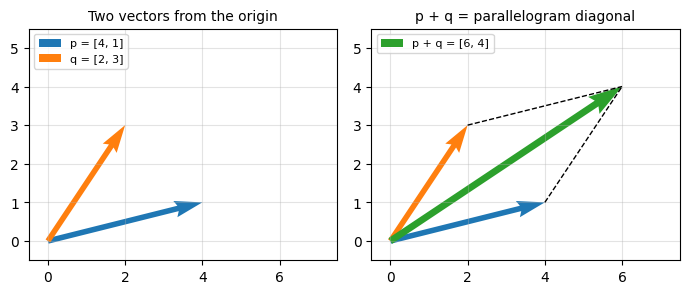

p + q = [6. 4.]   (head-to-tail: p then q == q then p)


In [4]:
p = np.array([4.0, 1.0])
q = np.array([2.0, 3.0])
s = p + q

fig, axes = plt.subplots(1, 2, figsize=(7, 3.2))
for ax in axes:
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.35)
    ax.set_xlim(-0.5, 7.5)
    ax.set_ylim(-0.5, 5.5)

# left: the two vectors alone
axes[0].quiver(0, 0, p[0], p[1], angles="xy", scale_units="xy", scale=1,
               color="tab:blue", width=0.018, label="p = [4, 1]")
axes[0].quiver(0, 0, q[0], q[1], angles="xy", scale_units="xy", scale=1,
               color="tab:orange", width=0.018, label="q = [2, 3]")
axes[0].legend(fontsize=8, loc="upper left")
axes[0].set_title("Two vectors from the origin", fontsize=10)

# right: parallelogram rule
axes[1].quiver(0, 0, p[0], p[1], angles="xy", scale_units="xy", scale=1,
               color="tab:blue", width=0.018)
axes[1].quiver(0, 0, q[0], q[1], angles="xy", scale_units="xy", scale=1,
               color="tab:orange", width=0.018)
axes[1].plot([p[0], s[0]], [p[1], s[1]], "k--", lw=1)      # p then q
axes[1].plot([q[0], s[0]], [q[1], s[1]], "k--", lw=1)      # q then p
axes[1].quiver(0, 0, s[0], s[1], angles="xy", scale_units="xy", scale=1,
               color="tab:green", width=0.022, label="p + q = [6, 4]")
axes[1].legend(fontsize=8, loc="upper left")
axes[1].set_title("p + q = parallelogram diagonal", fontsize=10)

plt.tight_layout()
plt.show()
print("p + q =", s, "  (head-to-tail: p then q == q then p)")


**Section notes — vectors:**

| Concept | Code |
|---|---|
| create | `np.array([3, 4])` (1-D = vector) |
| add / subtract / scale | `u + v`, `u - v`, `k * u` |
| components | `v[0]`, `v[1]` |
| shape discipline | `row (1,n)`, `col (n,1)`, plain `(n,)` |
| draw | `ax.quiver(0, 0, vx, vy, angles='xy', scale_units='xy', scale=1)` |

> **Gotcha:** `np.array([3,4]) + np.array([[1],[2]])` broadcasts into a
> `(2,2)` matrix — convenient, but *not* vector addition. Reshape explicitly
> when dimensions matter.

---
## 2. Dot product, angle & cosine similarity

▶ Mastering Vectors in Linear Algebra - Part 1: https://www.youtube.com/watch?v=mQewAJb8oJ8

### Definition & formulas
For $\mathbf u, \mathbf v \in \mathbb R^n$:
$$\mathbf u \cdot \mathbf v = \sum_{i=1}^n u_i v_i = \|\mathbf u\|\,\|\mathbf v\|\cos\theta$$
- `np.dot(u, v)` and `u @ v` compute it (identical for 1-D arrays).
- Rearranged: $\cos\theta = \dfrac{\mathbf u\cdot\mathbf v}{\|\mathbf u\|\|\mathbf v\|}$
  → **angle**, and the **cosine similarity** (normalise the dot product to $[-1, 1]$).
- **Geometric reading:** $\mathbf u\cdot\mathbf v = \|\mathbf v\| \times$
  (length of the projection of $\mathbf u$ onto $\mathbf v$) — positive (same
  direction), zero (orthogonal), negative (opposite).
- **Properties:** commutative $\mathbf u\cdot\mathbf v = \mathbf v\cdot\mathbf u$,
  distributive over `+`, $k(\mathbf u\cdot\mathbf v) = (k\mathbf u)\cdot\mathbf v$,
  and $\mathbf u\cdot\mathbf u = \|\mathbf u\|^2$.

In [5]:
u = np.array([1.0, 2, 3])
v = np.array([4.0, -5, 6])

print("np.dot(u, v) =", np.dot(u, v))
print("u @ v        =", u @ v)
print("manual sum   =", sum(u[i] * v[i] for i in range(3)))
print("u . u = ||u||^2 :", np.dot(u, u), "==", np.linalg.norm(u) ** 2)

# angle between the vectors
cos_t = np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))
theta = np.degrees(np.arccos(np.clip(cos_t, -1, 1)))
print("cos(theta) = %.4f   theta = %.2f degrees" % (cos_t, theta))

# properties
w = np.array([0.0, 1, -2])
k = 3.0
print("commutative :", np.isclose(np.dot(u, v), np.dot(v, u)))
print("distributive:", np.isclose(np.dot(u, v + w), np.dot(u, v) + np.dot(u, w)))
print("scalar pullout:", np.isclose(np.dot(k * u, v), k * np.dot(u, v)))


np.dot(u, v) = 12.0
u @ v        = 12.0
manual sum   = 12.0
u . u = ||u||^2 : 14.0 == 14.0
cos(theta) = 0.3655   theta = 68.56 degrees
commutative : True
distributive: True
scalar pullout: True


### Orthogonal vectors — `u · v = 0`
Orthogonal = perpendicular. It is the single most reused idea in ML:
residuals ⊥ fitted values, PCA components ⊥ each other, and a word embedding
at 90° means "unrelated".

In [6]:
print("dot([1,-1], [1,1])   =", np.dot([1, -1], [1, 1]), "-> orthogonal")
print("dot([2,0], [0,5])     =", np.dot([2, 0], [0, 5]), "-> orthogonal")
print("dot([1,1], [1,1])     =", np.dot([1, 1], [1, 1]), "-> same direction (not unit)")


dot([1,-1], [1,1])   = 0 -> orthogonal
dot([2,0], [0,5])     = 0 -> orthogonal
dot([1,1], [1,1])     = 2 -> same direction (not unit)


### `cosine_similarity` — the text-similarity workhorse
Compare documents as bags of words: each document is a vector of term counts,
and $ \text{sim}(A,B) = \dfrac{A\cdot B}{\|A\|\|B\|} \in [-1,1]$ (0 = unrelated,
1 = identical direction) — it ignores *length* (a short and a long review about
the same topic still match).

In [7]:
vocab = ["data", "model", "food", "recipe"]          # term vocabulary
docs = pd.DataFrame({                                 # term counts per document
    "docA": [5, 3, 0, 0],   # ML review
    "docB": [4, 2, 0, 1],   # ML review (short)
    "docC": [0, 0, 6, 4],   # recipe
}, index=vocab).T

def cosine(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

M = docs.to_numpy(dtype=float)
names = docs.index.tolist()
print("cosine similarity matrix:")
for i, ni in enumerate(names):
    for j, nj in enumerate(names):
        if j >= i:
            print("  %-4s vs %-4s : %.3f" % (ni, nj, cosine(M[i], M[j])))
# NOTE: sklearn has sklearn.metrics.pairwise.cosine_similarity for real work


cosine similarity matrix:
  docA vs docA : 1.000
  docA vs docB : 0.973
  docA vs docC : 0.000
  docB vs docB : 1.000
  docB vs docC : 0.121
  docC vs docC : 1.000


**Section notes — dot product:**

| Task | Code |
|---|---|
| dot product | `np.dot(u, v)` or `u @ v` |
| cosine similarity | `u @ v / (norm(u) * norm(v))` |
| angle | `np.degrees(np.arccos(cos))` |
| orthogonality test | `np.isclose(u @ v, 0)` |
| projection of u on v | `(u @ v) / (v @ v) * v` (section 13) |

---
## 3. Norms, unit vectors & distances

▶ Mastering Vectors in Linear Algebra - Part 1: https://www.youtube.com/watch?v=mQewAJb8oJ8

### `np.linalg.norm(x, ord=None, axis=None)`
**What it does:** measures the "length/size" of a vector or matrix.
**Syntax:** `np.linalg.norm(x, ord=None)`
**Parameters:** `ord` — order of the norm:

| `ord` | Name | Formula | Also known as |
|---|---|---|---|
| `1` | L1 | $\sum \|x_i\|$ | Manhattan / taxicab |
| `2` (default) | L2 | $\sqrt{\sum x_i^2}$ | Euclidean |
| `np.inf` | L∞ | $\max \|x_i\|$ | Chebyshev |
| any `p` | Lp | $(\sum \|x_i\|^p)^{1/p}$ | Minkowski (p=2 → Euclidean) |

**Returns:** a float (vector) or a matrix norm (2-D input; `ord=None` on a
matrix means the Frobenius norm).

**When L1 vs L2?** L2 spreads weight over many features (used everywhere:
gradients, distances, ridge). L1 keeps solutions **sparse** (absolute value has
a corner at 0 → Lasso regression zeroes out unimportant features); it is also
robust to outliers since it grows linearly.

In [8]:
v = np.array([3.0, -4.0])
print("L1  = %.4f  (|3| + |-4| = 7)" % np.linalg.norm(v, ord=1))
print("L2  = %.4f  (sqrt(9+16) = 5)" % np.linalg.norm(v, ord=2))
print("Loo = %.4f  (max |.| = 4)" % np.linalg.norm(v, ord=np.inf))
p = 3
print("L%d  = %.4f" % (p, (np.abs(v) ** p).sum() ** (1 / p)))
print("Minkowski p=2 == Euclidean:",
      np.isclose(np.linalg.norm(v, ord=2), (np.abs(v) ** 2).sum() ** 0.5))

# unit vector: v / ||v||  -> norm exactly 1
unit = v / np.linalg.norm(v)
print("unit v =", np.round(unit, 6), "  ||unit|| =", round(np.linalg.norm(unit), 12))


L1  = 7.0000  (|3| + |-4| = 7)
L2  = 5.0000  (sqrt(9+16) = 5)
Loo = 4.0000  (max |.| = 4)
L3  = 4.4979
Minkowski p=2 == Euclidean: True
unit v = [ 0.6 -0.8]   ||unit|| = 1.0


In [9]:
# distances between two points
a = np.array([1.0, 2.0, 3.0])
b = np.array([4.0, 0.0, 1.0])

manhattan = np.sum(np.abs(a - b))                 # L1 distance
euclidean = np.linalg.norm(a - b)                 # L2 distance
chebyshev = np.max(np.abs(a - b))                 # L-inf distance
minkowski3 = np.sum(np.abs(a - b) ** 3) ** (1 / 3)
print("L1 (Manhattan)  : %.4f" % manhattan)
print("L2 (Euclidean)  : %.4f" % euclidean)
print("L-inf (Chebyshev): %.4f" % chebyshev)
print("L3 (Minkowski)  : %.4f" % minkowski3)

# Hamming distance: fraction of DISAGREEING entries (categorical/equal length)
s1 = np.array(list("abracadabra"))                 # 11 characters
s2 = np.array(list("alabamarama"))                 # must be the SAME length
print("Hamming('abracadabra','alabamarama') = %.3f  (%d of %d differ)"
      % (np.mean(s1 != s2), (s1 != s2).sum(), len(s1)))


L1 (Manhattan)  : 7.0000
L2 (Euclidean)  : 4.1231
L-inf (Chebyshev): 3.0000
L3 (Minkowski)  : 3.5034
Hamming('abracadabra','alabamarama') = 0.818  (9 of 11 differ)


In [10]:
# pairwise distance matrix: broadcasting (n, d) -> (n, n, d) -> (n, n)
pts = np.array([[0.0, 0.0],
                [3.0, 4.0],
                [1.0, 1.0]])
D2 = np.linalg.norm(pts[:, None, :] - pts[None, :, :], axis=-1)   # Euclidean
D1 = np.abs(pts[:, None, :] - pts[None, :, :]).sum(axis=-1)       # Manhattan
print("Euclidean distance matrix:\n", D2)
print("Manhattan distance matrix:\n", D1)
print("symmetric:", np.allclose(D2, D2.T), " zero diagonal:", np.allclose(np.diag(D2), 0))


Euclidean distance matrix:
 [[0.         5.         1.41421356]
 [5.         0.         3.60555128]
 [1.41421356 3.60555128 0.        ]]
Manhattan distance matrix:
 [[0. 7. 2.]
 [7. 0. 5.]
 [2. 5. 0.]]
symmetric: True  zero diagonal: True


**Section notes — norms:**

| Task | Code |
|---|---|
| Euclidean length | `np.linalg.norm(v)` |
| L1 / L-inf | `np.linalg.norm(v, ord=1)` / `ord=np.inf` |
| normalise | `v / np.linalg.norm(v)` |
| pairwise distances | `np.linalg.norm(pts[:, None] - pts[None, :], axis=-1)` |
| Hamming | `np.mean(a != b)` |

> **Gotcha:** `np.linalg.norm(matrix)` without `ord` is the **Frobenius**
> norm ($\sqrt{\sum_{ij} a_{ij}^2}$), *not* a vector norm — and for a 1-D
> vector `ord=2` is the default. Matrix `ord=1`/`ord=np.inf` mean largest
> column/row sum instead.

---
## 4. Span, linear independence, basis & rank

▶ Mastering Vectors in Linear Algebra - Part 1: https://www.youtube.com/watch?v=mQewAJb8oJ8

### Definitions (the theory you must be able to state)
- **Linear combination:** $c_1\mathbf v_1 + \dots + c_k\mathbf v_k$.
- **Span:** the set of *all* linear combinations — `span{v1..vk}` is a line
  (k=1), plane (k=2 in ℝ³), or a subspace.
- **Linear independence:** the only solution of $c_1\mathbf v_1+\dots+c_k\mathbf v_k=\mathbf 0$
  is all $c_i = 0$. If some $c_i \ne 0$ works, one vector is a combination of
  the others → **dependent** (redundant information).
- **Basis:** a *minimal spanning* set — linearly independent **and** spans.
- **Dimension:** number of vectors in a basis = **rank** of the matrix built
  from them (columns = vectors).
- **Column space** $C(A)$ = span of columns; **row space** = span of rows;
  **null space** = $\{\mathbf x : A\mathbf x = \mathbf 0\}$.
  **Rank–nullity:** $\text{rank}(A) + \dim\text{null}(A) = n$ (columns).

In [11]:
# rank = dimension of the span = number of independent columns
indep = np.array([[1.0, 0, 0],
                  [0, 1, 0],
                  [0, 0, 1]])
dep = np.array([[1.0, 2, 3],
                [2, 4, 6],          # = 2 x row 1  (redundant)
                [1, 1, 1]])
print("rank(independent 3x3):", np.linalg.matrix_rank(indep))
print("rank(dependent  3x3):", np.linalg.matrix_rank(dep), "-> only 2 dimensions used")

# two vectors: v2 = 2*v1 -> span is a LINE, not a plane
v1 = np.array([1.0, 2.0])
v2 = 2 * v1
print("rank([v1 v2]) =", np.linalg.matrix_rank(np.column_stack([v1, v2])),
      "-> dependent")

# null space of a rank-deficient matrix (SciPy)
A = np.array([[1.0, 2, 3],
              [2, 4, 6],
              [1, 1, 1]])
ns = sla.null_space(A)
print("null space basis shape:", ns.shape,
      " A @ ns =\n", np.round(A @ ns, 12))
print("rank + null dim =", np.linalg.matrix_rank(A) + ns.shape[1],
      "(= n =", A.shape[1], ")")


rank(independent 3x3): 3
rank(dependent  3x3): 2 -> only 2 dimensions used
rank([v1 v2]) = 1 -> dependent
null space basis shape: (3, 1)  A @ ns =
 [[-0.]
 [-0.]
 [-0.]]
rank + null dim = 3 (= n = 3 )


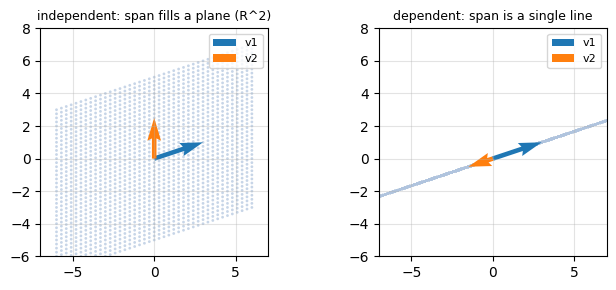

In [12]:
# visual: two independent vectors span a plane; two dependent vectors a line
fig, axes = plt.subplots(1, 2, figsize=(7, 3))
pairs = [([np.array([3.0, 1]), np.array([0.0, 2.5])],
          "independent: span fills a plane (R^2)"),
         ([np.array([3.0, 1]), np.array([-1.5, -0.5])],
          "dependent: span is a single line")]
c1, c2 = np.meshgrid(np.linspace(-2, 2, 41), np.linspace(-2, 2, 41))
for ax, (vecs, title) in zip(axes, pairs):
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.35)
    ax.set_xlim(-7, 7)
    ax.set_ylim(-6, 8)
    # scatter every linear combination c1*v1 + c2*v2 (coefficients in [-2, 2])
    span = c1.ravel()[:, None] * vecs[0] + c2.ravel()[:, None] * vecs[1]
    ax.scatter(span[:, 0], span[:, 1], s=4, color="lightsteelblue",
               alpha=0.7, edgecolors="none")
    for i, vec in enumerate(vecs):
        ax.quiver(0, 0, vec[0], vec[1], angles="xy", scale_units="xy", scale=1,
                  color=["tab:blue", "tab:orange"][i], width=0.02,
                  label=["v1", "v2"][i])
    ax.legend(fontsize=8, loc="upper right")
    ax.set_title(title, fontsize=9)
plt.tight_layout()
plt.show()


**Section notes — span & independence:**

| Question | Code |
|---|---|
| how many independent columns? | `np.linalg.matrix_rank(A)` |
| null space basis | `scipy.linalg.null_space(A)` |
| check `Ax = 0` | `np.allclose(A @ ns, 0)` |
| rank–nullity | `rank + ns.shape[1] == n_cols` |
| dependent pair | `np.linalg.matrix_rank(np.column_stack([v1, v2])) < 2` |

> **Gotcha:** rank ≤ min(rows, cols). A *tall* full-rank matrix has full
> **column** rank (independent features); a *wide* one has full **row** rank.
> `matrix_rank` uses singular values (§12), with tolerance `max(m,n)·eps·s_max`.

---
## 5. Matrices — notation & the types you must recognise

▶ Linear Algebra Part 2 | Matrices: https://www.youtube.com/watch?v=Y8UjSNSMeZ4

### Notation
$A = [a_{ij}]$ is an $m \times n$ matrix — $i$ = row (1..m), $j$ = column (1..n);
$a_{ij}$ lives in row $i$, column $j$. A $1\times n$ matrix *is* a row vector,
$m \times 1$ a column vector.

| Type | Definition | Check |
|---|---|---|
| square | $m = n$ | `A.shape[0] == A.shape[1]` |
| identity $I$ | 1s on diagonal, 0 elsewhere | `np.eye(n)` |
| diagonal | non-zero only on diagonal | `np.diag(v)` |
| symmetric | $A = A^\top$ | `np.allclose(A, A.T)` |
| skew-symmetric | $A = -A^\top$ (zero diagonal) | `np.allclose(A, -A.T)` |
| orthogonal | $A^\top A = AA^\top = I$ (columns unit & ⊥) | `np.allclose(A.T @ A, I)` |
| upper / lower triangular | 0 below / above diagonal | `np.allclose(A, np.triu(A))` |
| permutation | exactly one 1 per row/column | orthogonal + integer |
| sparse | mostly zeros | `scipy.sparse` (memory) |
| identity-neutral | $AI = IA = A$ | `np.allclose(A @ np.eye(n), A)` |

In [13]:
A = np.array([[2.0, 1, 1],
              [1, 2, 1],
              [1, 1, 2]])
I3 = np.eye(3)
D = np.diag([1.0, 2, 3])
S = np.array([[1.0, 2], [2, 1]])               # symmetric
Sk = np.array([[0.0, 2], [-2, 0]])             # skew-symmetric
Q = np.array([[0.0, -1], [1, 0]])              # 90° rotation
P = np.array([[0.0, 1, 0], [0, 0, 1], [1, 0, 0]])  # permutation
U = np.triu(np.array([[1.0, 2, 3], [4, 5, 6], [7, 8, 9]]))
L = np.tril(np.array([[1.0, 2, 3], [4, 5, 6], [7, 8, 9]]))

checks = {
    "A square":                 A.shape[0] == A.shape[1],
    "A symmetric (A = A^T)":    np.allclose(A, A.T),
    "A has 1s on diagonal?":    np.allclose(np.diag(A), 1),
    "S symmetric":              np.allclose(S, S.T),
    "Sk skew-symmetric":        np.allclose(Sk, -Sk.T) and np.allclose(np.diag(Sk), 0),
    "Q orthogonal (Q^T Q = I)": np.allclose(Q.T @ Q, np.eye(2)),
    "P orthogonal":             np.allclose(P.T @ P, np.eye(3)),
    "U upper triangular":       np.allclose(U, np.triu(U)),
    "L lower triangular":       np.allclose(L, np.tril(L)),
    "identity is neutral":      np.allclose(A @ I3, A) and np.allclose(I3 @ A, A),
}
for name, ok in checks.items():
    print("%-28s %s" % (name, ok))

print("\nidentity:\n", I3)
print("diagonal D:\n", D, " <- np.diag on 1-D builds, on 2-D extracts")
print("extract diagonal of A:", np.diag(A))


A square                     True
A symmetric (A = A^T)        True
A has 1s on diagonal?        False
S symmetric                  True
Sk skew-symmetric            True
Q orthogonal (Q^T Q = I)     True
P orthogonal                 True
U upper triangular           True
L lower triangular           True
identity is neutral          True

identity:
 [[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
diagonal D:
 [[1. 0. 0.]
 [0. 2. 0.]
 [0. 0. 3.]]  <- np.diag on 1-D builds, on 2-D extracts
extract diagonal of A: [2. 2. 2.]


**Section notes — matrix types:**

| Type | Algebraic signature |
|---|---|
| symmetric | $A = A^\top$ (real eigenvalues, §10) |
| skew-symmetric | $A = -A^\top$ (purely imaginary eigenvalues) |
| orthogonal | $A^\top A = I$ ⇒ $A^{-1} = A^\top$ (lengths & angles preserved) |
| identity | $AI = A$ (multiplication's "1") |
| permutation | reorders rows/columns; orthogonal with 0/1 entries |
| triangular | eigenvalues sit on the diagonal |

> **TIP:** a **correlation matrix is symmetric** with a diagonal of 1s and a
> **covariance matrix is symmetric positive semi-definite** — properties you
> will exploit in §11.

---
## 6. Matrix operations — `@` vs `*`, transpose rules, Frobenius

▶ Linear Algebra Part 2 | Matrices: https://www.youtube.com/watch?v=Y8UjSNSMeZ4

In [14]:
A = np.array([[1.0, 2], [3, 4]])
B = np.array([[5.0, 6], [7, 8]])
C = np.array([[1.0, 0], [0, -1]])

print("A + B =\n", A + B)                 # element-wise (same shape required)
print("2 * A =\n", 2 * A)                 # scalar multiplication
print("A.T =\n", A.T)                     # transpose (property, not a method)
print("A * B  (Hadamard, element-wise):\n", A * B)
print("A @ B  (matrix multiplication):\n", A @ B)
print("np.dot(A, B) == A @ B for 2-D:", np.allclose(np.dot(A, B), A @ B))


A + B =
 [[ 6.  8.]
 [10. 12.]]
2 * A =
 [[2. 4.]
 [6. 8.]]
A.T =
 [[1. 3.]
 [2. 4.]]
A * B  (Hadamard, element-wise):
 [[ 5. 12.]
 [21. 32.]]
A @ B  (matrix multiplication):
 [[19. 22.]
 [43. 50.]]
np.dot(A, B) == A @ B for 2-D: True


In [15]:
# THE @ vs * GOTCHA — shapes decide everything
X = np.arange(6, dtype=float).reshape(2, 3)     # (2, 3)
Y = np.arange(6, 12, dtype=float).reshape(2, 3) # (2, 3)

print("X shape", X.shape, " Y shape", Y.shape)
print("(X * Y).shape =", (X * Y).shape, " -> element-wise: same shapes, any shapes")
try:
    X @ Y
except ValueError as e:
    print("X @ Y -> ValueError:", str(e)[:80], "...")
print("(X @ Y.T).shape =", (X @ Y.T).shape,
      " -> matrix mult needs inner dims: (m, k) @ (k, n)")

# matrix multiplication rules
print("\n(3,4) @ (4,5) ->", np.ones((3, 4)) @ np.ones((4, 5)))
print("(4,3) @ (4,3) -> impossible (inner 3 vs 4)")
print("(m,n) @ (n,)  ->", (np.ones((4, 3)) @ np.array([1.0, 2, 3])).shape,
      " (matrix acts on a vector = linear transform)")


X shape (2, 3)  Y shape (2, 3)
(X * Y).shape = (2, 3)  -> element-wise: same shapes, any shapes
X @ Y -> ValueError: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc sign ...
(X @ Y.T).shape = (2, 2)  -> matrix mult needs inner dims: (m, k) @ (k, n)

(3,4) @ (4,5) -> [[4. 4. 4. 4. 4.]
 [4. 4. 4. 4. 4.]
 [4. 4. 4. 4. 4.]]
(4,3) @ (4,3) -> impossible (inner 3 vs 4)
(m,n) @ (n,)  -> (4,)  (matrix acts on a vector = linear transform)


In [16]:
# properties: associative YES, commutative NO, identity is neutral
print("associative  (AB)C = A(BC):", np.allclose((A @ B) @ C, A @ (B @ C)))
print("commutative  AB = BA      :", np.allclose(A @ B, B @ A),
      "<- AB != BA in general")
print("AB =\n", A @ B, "\nBA =\n", B @ A)
print("identity     AI = IA = A  :", np.allclose(A @ np.eye(2), A))
print("distributive A(B+C)=AB+AC :", np.allclose(A @ (B + C), A @ B + A @ C))

# transpose rules, verified
print("\n(A.T).T == A            :", np.allclose(A.T.T, A))
print("(AB).T == B.T A.T (FLIP) :", np.allclose((A @ B).T, B.T @ A.T))
print("AB.T vs A.T B.T (wrong!) :", np.allclose((A @ B).T, A.T @ B.T))


associative  (AB)C = A(BC): True
commutative  AB = BA      : False <- AB != BA in general
AB =
 [[19. 22.]
 [43. 50.]] 
BA =
 [[23. 34.]
 [31. 46.]]
identity     AI = IA = A  : True
distributive A(B+C)=AB+AC : True

(A.T).T == A            : True
(AB).T == B.T A.T (FLIP) : True
AB.T vs A.T B.T (wrong!) : False


In [17]:
# dot product of matrices, Frobenius norm, Hadamard (element-wise) use cases
print("np.dot(A, B) (same as A@B for 2-D):\n", np.dot(A, B))
print("Frobenius ||A||_F = sqrt(sum a_ij^2): %.4f" % np.linalg.norm(A, ord="fro"),
      " == sqrt(sum A**2): %.4f" % np.sqrt((A ** 2).sum()))

# Hadamard = feature-wise gating: what attention/GRU layers do before summing
features = np.array([[1.0, 2, 3],
                     [4, 5, 6]])            # two rows = two items, 3 features
gates = np.array([[0.0, 1, 0],              # keep only middle feature
                  [1, 0, 1]])               # keep 1st & 3rd
print("features * gates (element-wise masking):\n", features * gates)
print("features @ weights would mix features instead:",
      (features @ np.ones((3, 2))).shape, "(2,2)")


np.dot(A, B) (same as A@B for 2-D):
 [[19. 22.]
 [43. 50.]]
Frobenius ||A||_F = sqrt(sum a_ij^2): 5.4772  == sqrt(sum A**2): 5.4772
features * gates (element-wise masking):
 [[0. 2. 0.]
 [4. 0. 6.]]
features @ weights would mix features instead: (2, 2) (2,2)


**Section notes — operations:**

| Operation | Code | Shape rule |
|---|---|---|
| add / scalar | `A + B`, `k * A` | identical shapes |
| transpose | `A.T` | $(m,n) \to (n,m)$ |
| **element-wise** | `A * B` (Hadamard) | identical shapes (or broadcast) |
| **matrix product** | `A @ B` / `np.dot(A, B)` | $(m,k)@(k,n) \to (m,n)$ |
| Frobenius norm | `np.linalg.norm(A, 'fro')` | scalar |
| transpose rule | $(AB)^\top = B^\top A^\top$ | **order flips** |

> **Gotcha:** `A * B` **never** does matrix multiplication in numpy — that is
> always `A @ B` (Python 3.5+). For 1-D operands `np.dot(u, v)` = inner product,
> `np.dot(u, M)` = linear combination of rows, `np.dot(M, u)` = linear combo of cols.

---
## 7. Determinant — area scaling & singularity

▶ Linear Algebra Part 3 | Matrices Intuition: https://www.youtube.com/watch?v=7IV56bGTJTQ

### Definition
- **2×2:** $\det\begin{pmatrix}a&b\\c&d\end{pmatrix} = ad - bc$ (signed area of
  the parallelogram formed by the columns).
- **3×3 (cofactor expansion along row 1):**
  $\det(A) = a_{11}(a_{22}a_{33}-a_{23}a_{32}) - a_{12}(a_{21}a_{33}-a_{23}a_{31}) + a_{13}(a_{21}a_{32}-a_{22}a_{31})$
- **n×n:** sum over permutations (that's $O(n!)$ by definition — numpy uses LU).

**Meaning:** $\det(A)$ = factor by which $A$ scales **signed area/volume**;
$\det(A) = 0$ ⇔ the transform **squashes** space ⇔ columns are linearly
dependent ⇔ **no inverse** ⇔ $A\mathbf x = \mathbf 0$ has non-trivial solutions.

In [18]:
A = np.array([[4.0, 7], [2, 6]])
B = np.array([[1.0, 2], [3, 4]])
print("2x2: np.linalg.det(A) = %.4f   (ad - bc = %d)"
      % (np.linalg.det(A), int(4 * 6 - 7 * 2)))

C3 = np.array([[1.0, 2, 3],
               [0, 1, 4],
               [5, 6, 0]])
print("3x3: det = %.4f" % np.linalg.det(C3))
print("sympy exact det   =", sp.Matrix(C3.tolist()).det())   # cofactor expansion, exact

# properties (numerically, so use np.isclose)
print("\ndet(AB) = det(A)det(B) :", np.isclose(np.linalg.det(A @ B),
                                              np.linalg.det(A) * np.linalg.det(B)))
print("det(A.T) = det(A)      :", np.isclose(np.linalg.det(A.T), np.linalg.det(A)))
print("det(kA) = k^n det(A)   :", np.isclose(np.linalg.det(2 * A),
                                              2 ** 2 * np.linalg.det(A)))
print("det(A^-1) = 1/det(A)   :", np.isclose(np.linalg.det(np.linalg.inv(A)),
                                              1 / np.linalg.det(A)))


2x2: np.linalg.det(A) = 10.0000   (ad - bc = 10)
3x3: det = 1.0000
sympy exact det   = 1.00000000000000

det(AB) = det(A)det(B) : True
det(A.T) = det(A)      : True
det(kA) = k^n det(A)   : True
det(A^-1) = 1/det(A)   : True


In [19]:
# singularity: det = 0 <=> no inverse <=> dependent columns
S = np.array([[1.0, 2],
              [2, 4]])                       # column 2 = 2 x column 1
print("det(S) = %.3e (numerically 0)" % np.linalg.det(S))
print("rank(S) =", np.linalg.matrix_rank(S), "(< 2 -> columns dependent)")
try:
    np.linalg.inv(S)
except np.linalg.LinAlgError as e:
    print("inv(S) -> LinAlgError:", e)
print("S @ [2, -1]^T =", S @ np.array([2.0, -1]), " (non-trivial null vector)")

print("\ndet of a singular 3x3 (row3 = row1 + row2):",
      "%.3e" % np.linalg.det(np.array([[1.0, 2, 3],
                                        [4, 5, 6],
                                        [5.0, 7, 9]])))


det(S) = 0.000e+00 (numerically 0)
rank(S) = 1 (< 2 -> columns dependent)
inv(S) -> LinAlgError: Singular matrix
S @ [2, -1]^T = [0. 0.]  (non-trivial null vector)

det of a singular 3x3 (row3 = row1 + row2): 1.066e-15


In [20]:
# determinant = area/volume scaling factor (visual + numbers)
square = np.array([[0.0, 0], [1, 0], [1, 1], [0, 1]])   # unit square, area 1

def poly_area(P):                                        # shoelace formula
    x, y = P[:, 0], P[:, 1]
    return 0.5 * abs(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1)))

M = np.array([[2.0, 0.5],
              [0.5, 1.5]])
transformed = square @ M.T                                # apply M to each point
print("area of unit square      = %.4f" % poly_area(square))
print("area after transform     = %.4f" % poly_area(transformed))
print("|det(M)| x original area = %.4f" % (abs(np.linalg.det(M)) * poly_area(square)))
print("det(M) = %.4f (positive -> orientation preserved)" % np.linalg.det(M))


area of unit square      = 1.0000
area after transform     = 2.7500
|det(M)| x original area = 2.7500
det(M) = 2.7500 (positive -> orientation preserved)


**Section notes — determinant:**

| Fact | Statement |
|---|---|
| 2×2 | $ad - bc$ |
| meaning | signed area/volume scaling factor |
| `det = 0` | singular ⇔ dependent columns ⇔ no inverse |
| multiplicative | $\det(AB) = \det(A)\det(B)$ |
| transpose | $\det(A^\top) = \det(A)$ |
| scaling | $\det(kA) = k^n\det(A)$ for $n\times n$ |
| code | `np.linalg.det(A)` · exact: `sp.Matrix(A).det()` |

> **Gotcha:** `np.linalg.det` is a float — for badly scaled matrices it can
> return `-1.2e-17` instead of `0`. Never test `det == 0`; use
> `abs(det) < tol` or `np.linalg.matrix_rank`.

---
## 8. Inverse — `A A⁻¹ = I` and solving `Ax = b`

▶ Linear Algebra Part 3 | Matrices Intuition: https://www.youtube.com/watch?v=7IV56bGTJTQ

### `np.linalg.inv(A)`
**What it does:** finds $A^{-1}$ with $AA^{-1} = A^{-1}A = I$ (undo the transform).
**Exists only when $A$ is square and non-singular** ($\det A \ne 0$, full rank).
**Properties:**
$(A^{-1})^{-1} = A$ · $(AB)^{-1} = B^{-1}A^{-1}$ (**order flips**, like transpose) ·
$(A^\top)^{-1} = (A^{-1})^\top$ · $A^{-1}$ has the same *eigenvectors* with
eigenvalues $1/\lambda$.

**Solve `Ax = b` two ways:**
1. `np.linalg.inv(A) @ b`  — mathematically fine, **numerically wasteful and less stable**
2. `np.linalg.solve(A, b)` — **prefer this**: LU factorisation, no explicit inverse
   (this is what every serious library does under the hood).

In [21]:
A = np.array([[4.0, 7],
              [2, 6]])
A_inv = np.linalg.inv(A)
b = np.array([8.0, 6.0])

print("A^-1 =\n", np.round(A_inv, 6))
print("A @ A^-1 =\n", np.round(A @ A_inv, 12), " (identity)")

x_inv = A_inv @ b                    # way 1
x_solve = np.linalg.solve(A, b)      # way 2 (preferred)
print("\nvia inverse :", x_inv)
print("via solve   :", x_solve)
print("same answer  :", np.allclose(x_inv, x_solve))
print("verify A @ x = b :", np.allclose(A @ x_solve, b))


A^-1 =
 [[ 0.6 -0.7]
 [-0.2  0.4]]
A @ A^-1 =
 [[ 1. -0.]
 [ 0.  1.]]  (identity)

via inverse : [0.6 0.8]
via solve   : [0.6 0.8]
same answer  : True
verify A @ x = b : True


In [22]:
# ill-conditioned matrix: det ~ 0, huge condition number -> tiny changes in b
# blow up the answer (this is why explicit inverses are dangerous)
M = np.array([[1.0, 1.0],
              [1.0, 1.0000001]])
print("cond(M) = %.3e  (1.0 is perfect, huge = unstable)" % np.linalg.cond(M))
print("det(M)  = %.3e" % np.linalg.det(M))
print("solve(M, [2, 2.0000001]) =", np.linalg.solve(M, [2.0, 2.0000001]))
print("solve(M, [2, 2])         =", np.linalg.solve(M, [2.0, 2.0]),
      " <- b changed by 1e-7, x changed a lot")


cond(M) = 4.000e+07  (1.0 is perfect, huge = unstable)
det(M)  = 1.000e-07
solve(M, [2, 2.0000001]) = [1. 1.]
solve(M, [2, 2])         = [2. 0.]  <- b changed by 1e-7, x changed a lot


In [23]:
# pseudo-inverse for non-square / singular matrices (Moore-Penrose)
R = np.array([[0.0, 1, 2],
              [3, 4, 5]])                    # 2x3, full row rank
pinv_R = np.linalg.pinv(R)
print("R shape", R.shape, "-> pinv shape", pinv_R.shape)
print("pinv(R) @ R =\n", np.round(pinv_R @ R, 12),
      "\n(identity because rows are independent)")

S = np.array([[1.0, 2],
              [2, 4]])                       # singular
print("\npinv of a singular matrix:\n", np.linalg.pinv(S))
print("pinv(S) @ S (projection, NOT identity):\n", np.round(np.linalg.pinv(S) @ S, 6))
print("lstsq uses pinv internally: np.linalg.lstsq(S, b, rcond=None)")


R shape (2, 3) -> pinv shape (3, 2)
pinv(R) @ R =
 [[ 0.83333333  0.33333333 -0.16666667]
 [ 0.33333333  0.33333333  0.33333333]
 [-0.16666667  0.33333333  0.83333333]] 
(identity because rows are independent)

pinv of a singular matrix:
 [[0.04 0.08]
 [0.08 0.16]]
pinv(S) @ S (projection, NOT identity):
 [[0.2 0.4]
 [0.4 0.8]]
lstsq uses pinv internally: np.linalg.lstsq(S, b, rcond=None)


**Section notes — inverse:**

| Task | Code | Note |
|---|---|---|
| invert | `np.linalg.inv(A)` | square & non-singular only |
| solve `Ax=b` | `np.linalg.solve(A, b)` | **prefer over `inv(A) @ b`** |
| stability check | `np.linalg.cond(A)` | ≫ 1 → numerically dangerous |
| rank-deficient solve | `np.linalg.pinv(A)` / `lstsq` | minimum-norm solution |
| inverse rule | $(AB)^{-1} = B^{-1}A^{-1}$ | order flips |

> **Gotcha:** solving by the inverse costs $O(n^3)$ *twice* and squares the
> condition number; `solve` is both faster and more accurate. Also
> `inv(A)` on a singular matrix raises `np.linalg.LinAlgError`.

---
## 9. Systems of equations — `Ax = b`, rank & Gaussian elimination

▶ Linear Algebra Part 3 | Matrices Intuition: https://www.youtube.com/watch?v=7IV56bGTJTQ

### Matrix form & geometry
A system $a_{i1}x_1 + \dots + a_{in}x_n = b_i$ is $A\mathbf x = \mathbf b$:
each equation is a **line (2-D) / plane (3-D)**; a solution is a point where
**all** of them meet.

| rank(A) vs rank([A\|b]) | Meaning | Geometry (2 vars) |
|---|---|---|
| equal = n | **unique** solution | lines cross at one point |
| equal < n | **infinitely many** solutions | lines coincide / share a plane |
| rank(A) < rank([A\|b]) | **inconsistent** (no solution) | parallel distinct lines |

`rank([A|b])` is the rank of the **augmented** matrix (append b as a column).

In [24]:
# unique solution: 2x + y = 5 ; x - y = 1
A = np.array([[2.0, 1], [1, -1]])
b = np.array([5.0, 1.0])
print("x =", np.linalg.solve(A, b), "  (2x + y = 5, x - y = 1)")

# inconsistent: x + y = 1 ; x + y = 3   (parallel lines)
A1 = np.array([[1.0, 1], [1, 1]])
b1 = np.array([1.0, 3.0])
print("ranks: A =", np.linalg.matrix_rank(A1),
      "  [A|b] =", np.linalg.matrix_rank(np.column_stack([A1, b1])),
      "-> 1 < 2 => inconsistent")
try:
    np.linalg.solve(A1, b1)
except np.linalg.LinAlgError as e:
    print("solve -> LinAlgError:", e)

# infinitely many: x + y = 1 ; 2x + 2y = 2  (same line)
b2 = np.array([1.0, 2.0])
print("ranks: A =", np.linalg.matrix_rank(A1),
      "  [A|b] =", np.linalg.matrix_rank(np.column_stack([A1, b2])),
      "-> equal = 1 < n = 2 => infinite solutions")
print("lstsq returns ONE solution:", np.linalg.lstsq(A1, b2, rcond=None)[0],
      "(the minimum-norm one)")


x = [2. 1.]   (2x + y = 5, x - y = 1)
ranks: A = 1   [A|b] = 2 -> 1 < 2 => inconsistent
solve -> LinAlgError: Singular matrix
ranks: A = 1   [A|b] = 2 -> equal = 1 < n = 2 => infinite solutions
lstsq returns ONE solution: [0.75 0.75] (the minimum-norm one)


### Gaussian elimination intuition
Reduce the augmented matrix to **row echelon form** with elementary row ops
(swap, scale, add-multiple-of-row); back-substitution then reads off `x`.
Reduced row echelon form (RREF) finishes the job with zeros above *and* below
each pivot — `sympy.Matrix.rref()` does it exactly (rationals, no float noise).

In [25]:
# classic system: 2x + y - z = 8 ; -3x - y + 2z = -11 ; -2x + y + 2z = -3
M = sp.Matrix([[2, 1, -1, 8],
               [-3, -1, 2, -11],
               [-2, 1, 2, -3]])
rref, pivots = M.rref()
print("reduced row echelon form [A|b]:")
print(rref)
print("pivot columns:", pivots, "-> leading variables x, y, z")
print("solution: x = %s, y = %s, z = %s" % tuple(rref[i, -1] for i in range(3)))
# numpy floating-point equivalent (row echelon via elimination steps)
A_num = np.array([[2.0, 1, -1], [-3, -1, 2], [-2, 1, 2]])
b_num = np.array([8.0, -11, -3])
print("numpy solve:", np.linalg.solve(A_num, b_num))


reduced row echelon form [A|b]:
Matrix([[1, 0, 0, 2], [0, 1, 0, 3], [0, 0, 1, -1]])
pivot columns: (0, 1, 2) -> leading variables x, y, z
solution: x = 2, y = 3, z = -1
numpy solve: [ 2.  3. -1.]


**Section notes — linear systems:**

| Task | Code |
|---|---|
| solve | `np.linalg.solve(A, b)` |
| rank test | `np.linalg.matrix_rank(A)` vs `matrix_rank(np.column_stack([A, b]))` |
| exact elimination | `sp.Matrix([[...]]).rref()` |
| minimum-norm / least squares | `np.linalg.lstsq(A, b, rcond=None)` |
| geometric meaning | $A\mathbf x=\mathbf b$: intersect the rows' lines/planes |

> **Gotcha:** numpy's `solve` only tells you *it* failed (`LinAlgError` for
> exactly singular matrices). Diagnose *why* with ranks: equal ranks →
> solvable; unequal → inconsistent.

---
## 10. Eigenvalues & eigenvectors

▶ Session on Eigen Vectors and Eigen Values: https://www.youtube.com/watch?v=5HDkRG5gQHM

### Definition & characteristic polynomial
A non-zero vector $\mathbf v$ with $A\mathbf v = \lambda\mathbf v$ is an
**eigenvector**; $\lambda$ is its **eigenvalue** — $A$ only *stretches/reverses*
$\mathbf v$, it does not rotate it.
Derivation: $(A - \lambda I)\mathbf v = \mathbf 0$ has a non-trivial solution
iff $\det(A - \lambda I) = 0$ → the **characteristic polynomial** in $\lambda$.

**Worked 2×2 by hand** — $A = \begin{pmatrix}2&1\\1&2\end{pmatrix}$:
$$\det(A-\lambda I) = (2-\lambda)^2 - 1 = \lambda^2 - 4\lambda + 3 = 0
\Rightarrow \lambda = 3,\ 1$$
- $\lambda = 3$: $(A-3I)\mathbf v = \mathbf 0 \Rightarrow \mathbf v_1 = (1, 1)^\top$
- $\lambda = 1$: $(A-I)\mathbf v = \mathbf 0 \Rightarrow \mathbf v_2 = (1, -1)^\top$

In [26]:
A = np.array([[2.0, 1],
              [1, 2]])
w, V = np.linalg.eig(A)          # w = eigenvalues, V = COLUMNS are eigenvectors

print("eigenvalues      :", np.round(w, 6))
print("eigenvectors (columns of V):\n", np.round(V, 6))

# verify A v = lambda v for each
for i in range(len(w)):
    Av = A @ V[:, i]
    lam_v = w[i] * V[:, i]
    print("  col %d: A@v = %s   lambda*v = %s   match: %s"
          % (i, np.round(Av, 4), np.round(lam_v, 4), np.allclose(Av, lam_v)))
print("ALL verified:", all(np.allclose(A @ V[:, i], w[i] * V[:, i])
                           for i in range(len(w))))
print("eigenvector SCALE/SIGN is arbitrary — normalising:",
      np.round(V[:, 0] / np.linalg.norm(V[:, 0]), 4))


eigenvalues      : [3. 1.]
eigenvectors (columns of V):
 [[ 0.707107 -0.707107]
 [ 0.707107  0.707107]]
  col 0: A@v = [2.1213 2.1213]   lambda*v = [2.1213 2.1213]   match: True
  col 1: A@v = [-0.7071  0.7071]   lambda*v = [-0.7071  0.7071]   match: True
ALL verified: True
eigenvector SCALE/SIGN is arbitrary — normalising: [0.7071 0.7071]


In [27]:
# API tour: numpy, scipy, sympy — and complex eigenvalues
print("np.linalg.eigvals (values only):", np.round(np.linalg.eigvals(A), 4))
print("scipy.linalg.eig  :", np.round(sla.eig(A)[0], 4))     # complex dtype
print("sympy exact       :", sp.Matrix(A.tolist()).eigenvects())

# a matrix that ROTATES has no real eigenvectors -> complex eigenvalues
R90 = np.array([[0.0, -1], [1, 0]])          # 90° rotation
print("\n90-degree rotation eigenvalues:", np.linalg.eigvals(R90),
      " (purely imaginary -> no real invariant direction)")
print("NOTE: numpy may return complex values — always check np.isrealobj(w)")


np.linalg.eigvals (values only): [3. 1.]
scipy.linalg.eig  : [3.+0.j 1.+0.j]
sympy exact       : [(1.00000000000000, 1, [Matrix([
[-0.707106781186548],
[ 0.707106781186548]])]), (3.00000000000000, 1, [Matrix([
[-0.707106781186548],
[-0.707106781186548]])])]

90-degree rotation eigenvalues: [0.+1.j 0.-1.j]  (purely imaginary -> no real invariant direction)
NOTE: numpy may return complex values — always check np.isrealobj(w)


In [28]:
# diagonalisation A = P D P^-1, and the symmetric-matrix superpowers
P = V                       # eigenvectors as columns
D = np.diag(w)              # eigenvalues on the diagonal
print("A = P D P^-1 :", np.allclose(P @ D @ np.linalg.inv(P), A))
print("rebuild A:\n", np.round(P @ D @ np.linalg.inv(P), 6))

# A is symmetric => REAL eigenvalues and ORTHONORMAL eigenvectors (P orthogonal)
print("\nsymmetric A -> eigenvalues real:", np.isrealobj(w))
print("P^T P = I (orthonormal columns):", np.allclose(P.T @ P, np.eye(2)))
print("P^-1 = P^T (orthogonal!):", np.allclose(np.linalg.inv(P), P.T))


A = P D P^-1 : True
rebuild A:
 [[2. 1.]
 [1. 2.]]

symmetric A -> eigenvalues real: True
P^T P = I (orthonormal columns): True
P^-1 = P^T (orthogonal!): True


In [29]:
# power iteration: repeatedly apply A -> converges to the DOMINANT eigenvector
b = np.array([1.0, 0.5])
for _ in range(60):
    b = A @ b
    b /= np.linalg.norm(b)                    # renormalise to avoid overflow
print("dominant eigenvector (up to sign):", np.round(b, 4),
      " ~ (1,1)/sqrt(2) for lambda = 3")
print("A @ b =", np.round(A @ b, 4), "-> stretch factor",
      round(float(np.linalg.norm(A @ b)), 4), "= lambda_max =", round(max(w), 4))


dominant eigenvector (up to sign): [0.7071 0.7071]  ~ (1,1)/sqrt(2) for lambda = 3
A @ b = [2.1213 2.1213] -> stretch factor 3.0 = lambda_max = 3.0


In [30]:
# eigenvalues of a COVARIANCE matrix = variances along principal axes (PCA link)
rng = np.random.default_rng(0)
x = rng.normal(size=200)
y = 0.9 * x + rng.normal(0, 0.4, size=200)    # correlated feature
C = np.cov(np.column_stack([x, y]), rowvar=False)
evals = np.linalg.eigvalsh(C)                 # symmetric -> eigh (sorted ascending)

print("covariance matrix:\n", np.round(C, 4))
print("eigenvalues (ascending):", np.round(evals, 4))
print("explained variance ratio:", np.round(evals / evals.sum(), 4))
print("trace check: sum(eigs) = %.4f == trace(C) = %.4f"
      % (evals.sum(), np.trace(C)))
print("-> biggest eigenvalue = variance along the principal component (section 11)")


covariance matrix:
 [[0.9285 0.8099]
 [0.8099 0.8748]]
eigenvalues (ascending): [0.0913 1.7121]
explained variance ratio: [0.0506 0.9494]
trace check: sum(eigs) = 1.8034 == trace(C) = 1.8034
-> biggest eigenvalue = variance along the principal component (section 11)


**Section notes — eigen:**

| Task | Code |
|---|---|
| values + vectors | `w, V = np.linalg.eig(A)` (vectors = **columns**) |
| values only | `np.linalg.eigvals(A)` |
| verify | `np.allclose(A @ V[:, i], w[i] * V[:, i])` |
| diagonalise | `P @ np.diag(w) @ np.linalg.inv(P)` |
| symmetric matrices | real eigenvalues, orthonormal `V`, `V.T @ V = I` |
| exact | `sp.Matrix(A).eigenvects()` |
| dominant direction | power iteration: `b = A@b; b /= norm(b)` |

> **Gotcha:** eigenvalues only exist for **square** matrices (SVD §12 handles
> any shape), and they may come back **complex** for non-symmetric $A$.
> Eigenvector *sign and scale are arbitrary* — never compare them element-wise
> across libraries without fixing the sign (`np.allclose(v, -u)` is also "equal").

---
## 11. Eigen decomposition & PCA variants

▶ Session on Eigen Decomposition + PCA Variants: https://www.youtube.com/watch?v=D5IlO4lzaZ0

### The spectral theorem (why this all works for data)
For **real symmetric** $A$ (and any covariance/correlation matrix is symmetric!):
- all eigenvalues are **real**,
- eigenvectors for different eigenvalues are **orthogonal**,
- so $A = Q\Lambda Q^\top$ with $Q$ **orthogonal** ($Q^{-1} = Q^\top$).

**Positive (semi-)definiteness** — a symmetric matrix is
- **PD** (positive definite) iff every eigenvalue $> 0$ ⟺ $\mathbf x^\top A \mathbf x > 0$
  for all $\mathbf x \ne \mathbf 0$ ⟺ Cholesky factorisation exists.
- **PSD** iff every eigenvalue $\ge 0$ — covariance matrices are PSD (zero
  eigenvalue = redundant feature).

`eigh` vs `eig`: **symmetric/Hermitian → always `np.linalg.eigh`** (real,
ascending, orthonormal, faster & backward-stable). Use `np.linalg.eig` only for
non-symmetric matrices.

In [31]:
# PCA from scratch: standardise -> covariance -> eigh -> sort -> project
rng = np.random.default_rng(0)
n = 300
x1 = rng.normal(0, 1, n)
X = np.column_stack([x1,
                     0.9 * x1 + rng.normal(0, 0.4, n),
                     0.6 * x1 + rng.normal(0, 0.7, n)])
feature_names = ["x1", "x2", "x3"]

# (1) standardise: zero mean, unit variance (else high-variance features dominate)
Xs = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)
# (2) covariance matrix (3x3, symmetric)
C = np.cov(Xs, rowvar=False)
# (3) eigendecomposition of the symmetric covariance matrix
evals, evecs = np.linalg.eigh(C)
# (4) sort eigenvalues (and their vectors) descending
order = np.argsort(evals)[::-1]
evals, evecs = evals[order], evecs[:, order]
# (5) project the data onto the principal components
scores = Xs @ evecs

print("eigenvalues          :", np.round(evals, 4))
print("explained variance % :", np.round(100 * evals / evals.sum(), 2))
print("principal components (columns):\n", np.round(evecs, 3))
print("var(PC1) = %.4f  ==  eigenvalue1 %.4f"
      % (scores[:, 0].var(ddof=1), evals[0]))
print("cor(PC1, PC2) = %.8f  (components are orthogonal)"
      % np.corrcoef(scores[:, 0], scores[:, 1])[0, 1])
print("total variance preserved with all 3: %.4f"
      % (scores.var(axis=0, ddof=1).sum() / Xs.var(axis=0, ddof=1).sum()))


eigenvalues          : [2.5337 0.3908 0.0755]
explained variance % : [84.46 13.03  2.52]
principal components (columns):
 [[-0.602 -0.324 -0.73 ]
 [-0.594 -0.429  0.681]
 [-0.534  0.843  0.066]]
var(PC1) = 2.5337  ==  eigenvalue1 2.5337
cor(PC1, PC2) = -0.00000000  (components are orthogonal)
total variance preserved with all 3: 1.0000


In [32]:
# cross-check against scikit-learn (same result up to sign — signs are arbitrary)
pca_sk = PCA().fit(Xs)
print("sklearn ratios :", np.round(pca_sk.explained_variance_ratio_, 4))
print("numpy  ratios  :", np.round(evals / evals.sum(), 4))
print("components match up to sign:",
      np.allclose(np.abs(pca_sk.components_.T), np.abs(evecs), atol=1e-6))


sklearn ratios : [0.8446 0.1303 0.0252]
numpy  ratios  : [0.8446 0.1303 0.0252]
components match up to sign: True


In [33]:
# positive definiteness checks on the covariance matrix
print("eigenvalues of C :", np.round(np.linalg.eigvalsh(C), 4))
print("all > 0  -> positive definite:", bool(np.all(np.linalg.eigvalsh(C) > 0)))
L = np.linalg.cholesky(C)                       # C = L L^T, exists only for PD
print("Cholesky L L^T == C:", np.allclose(L @ L.T, C))

B = np.array([[1.0, 2], [2, 4]])                # singular: rank 1
print("\neig(B) =", np.round(np.linalg.eigvalsh(B), 4),
      "-> >= 0 (semi-definite) but not > 0")
try:
    np.linalg.cholesky(B)
except np.linalg.LinAlgError as e:
    print("cholesky(B) -> LinAlgError:", e)


eigenvalues of C : [0.0755 0.3908 2.5337]
all > 0  -> positive definite: True
Cholesky L L^T == C: True

eig(B) = [0. 5.] -> >= 0 (semi-definite) but not > 0
cholesky(B) -> LinAlgError: Matrix is not positive definite


### PCA variants — one-liners (what to reach for when)

| Variant | Idea | Code |
|---|---|---|
| standard PCA | eigendecomposition of covariance / SVD of data | above |
| **randomized PCA** | randomized SVD ≈ exact but much faster for large $n$ | `PCA(n_components=k, svd_solver='randomized')` |
| incremental / online | PCA for data that doesn't fit in memory | `sklearn.decomposition.IncrementalPCA` |
| **robust PCA** | split $X = \text{low-rank} + \text{sparse}$; sparse part = outliers | Principal Component Pursuit / `sklearn.decomposition` alternatives |
| **sparse PCA** | $\ell_1$-penalised loadings → each component uses few original features | `sklearn.decomposition.SparsePCA` |
| kernel PCA | non-linear structure via the kernel trick | `sklearn.decomposition.KernelPCA` |
| dual PCA | eigendecompose $XX^\top$ when $n \ll p$ (images, genes) | `X @ X.T` then `eigh` |

**Rule of thumb:** start with `PCA().fit(X)` (SVD-based, safe); switch to
`svd_solver='randomized'` for $n > 10^4$; use robust/sparse variants only when
outliers or interpretability demand it.

**Section notes — eigen + PCA:**

| Piece | Code |
|---|---|
| spectral theorem | symmetric $A = Q\Lambda Q^\top$ |
| symmetric eigen | `np.linalg.eigh(C)` (real, ascending, orthonormal) |
| positive definite | `np.all(eigvalsh(C) > 0)` · `np.linalg.cholesky(C)` |
| PCA steps | standardise → `np.cov` → `eigh` → sort → `Xs @ evecs` |
| explained variance | `evals / evals.sum()` |
| fast PCA | `PCA(svd_solver='randomized')` |

---
## 12. Singular Value Decomposition (SVD)

▶ Session on Singular Value Decomposition: https://www.youtube.com/watch?v=NPkMoUNkEtQ

### Definition — $A = U\,\Sigma\,V^\top$
**Any** $m \times n$ matrix splits into:

| Factor | Shape | Meaning |
|---|---|---|
| $U$ | $m \times m$ (full) / $m\times r$ (compact) | **left singular vectors** — orthonormal basis of the column space |
| $\Sigma$ | $m \times n$ / diagonal $r \times r$ | **singular values** $\sigma_1 \ge \sigma_2 \ge \dots \ge 0$ on the diagonal |
| $V^\top$ | $n \times n$ / $r \times n$ | **right singular vectors** — orthonormal basis of the row space |

$r = \min(m,n)$. Reading it as a recipe: $V^\top$ rotates/reflects → $\Sigma$
scales each axis by $\sigma_i$ → $U$ rotates/reflects again. **Eigendecomposition
is the special case of a square matrix; SVD works for every shape.**

**Relation to eigen:** $\sigma_i^2$ are the eigenvalues of $A^\top A$ (and of
$AA^\top$); columns of $V$ are the eigenvectors of $A^\top A$, columns of $U$
the eigenvectors of $AA^\top$. **Rank = number of $\sigma_i > 0$.**

In [34]:
A = np.array([[1.0, 0],
              [0, -2],
              [3, 1]])                      # 3 x 2 rectangular (eig cannot touch this)
U, s, Vt = np.linalg.svd(A, full_matrices=True)     # full: square U/Vt
Uc, sc, Vtc = np.linalg.svd(A, full_matrices=False)  # compact: thin U/Vt

print("full     U %s  s %s  Vt %s" % (U.shape, s.shape, Vt.shape))
print("compact  U %s  s %s  Vt %s" % (Uc.shape, sc.shape, Vtc.shape))
print("reconstruction (Uc * s) @ Vtc == A:", np.allclose((Uc * sc) @ Vtc, A))
print("U columns orthonormal:", np.allclose(Uc.T @ Uc, np.eye(2)),
      " V rows orthonormal:", np.allclose(Vtc @ Vtc.T, np.eye(2)))
print("singular values:", np.round(s, 4))

print("\ns^2 (sorted)      :", np.round(np.sort(s ** 2), 4))
print("eig(A^T A)        :", np.round(np.linalg.eigvalsh(A.T @ A), 4))
print("eig(A A^T)        :", np.round(np.linalg.eigvalsh(A @ A.T), 4),
      " <- extra 0: m - r = 1 zero")


full     U (3, 3)  s (2,)  Vt (2, 2)
compact  U (3, 2)  s (2,)  Vt (2, 2)
reconstruction (Uc * s) @ Vtc == A: True
U columns orthonormal: True  V rows orthonormal: True
singular values: [3.3771 1.896 ]

s^2 (sorted)      : [ 3.5949 11.4051]
eig(A^T A)        : [ 3.5949 11.4051]
eig(A A^T)        : [-0.      3.5949 11.4051]  <- extra 0: m - r = 1 zero


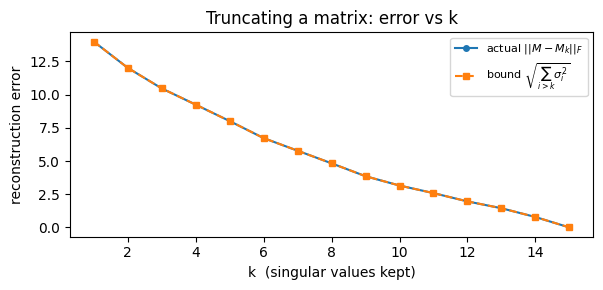

errors at k=1..5 : [13.9932 12.0168 10.4696  9.247   8.0096]
rank(M) = 15 -> error ~0 only when k reaches the rank


In [35]:
# low-rank approximation: keep the top-k singular values (Eckart-Young)
rng = np.random.default_rng(1)
M = rng.normal(size=(20, 15))
U, s, Vt = np.linalg.svd(M, full_matrices=False)
ks = np.arange(1, len(s) + 1)
errs = [np.linalg.norm(M - (U[:, :k] * s[:k]) @ Vt[:k], "fro") for k in ks]
bound = [np.sqrt((s[k:] ** 2).sum()) for k in ks]        # optimal error at rank k

fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(ks, errs, "o-", ms=4, label=r"actual $||M - M_k||_F$")
ax.plot(ks, bound, "s--", ms=4, label=r"bound $\sqrt{\sum_{i>k}\sigma_i^2}$")
ax.set_xlabel("k  (singular values kept)")
ax.set_ylabel("reconstruction error")
ax.set_title("Truncating a matrix: error vs k")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print("errors at k=1..5 :", np.round(errs[:5], 4))
print("rank(M) =", np.linalg.matrix_rank(M),
      "-> error ~0 only when k reaches the rank")


In [36]:
# structured example: rank-2 signal + noise -> truncated SVD denoises
rng = np.random.default_rng(2)
clean = (np.outer(rng.normal(size=8), rng.normal(size=6))
         + np.outer(rng.normal(size=8), rng.normal(size=6)))   # exact rank 2
noisy = clean + rng.normal(0, 0.3, size=clean.shape)
U, s, Vt = np.linalg.svd(noisy, full_matrices=False)
denoised = (U[:, :2] * s[:2]) @ Vt[:2]

print("||noisy  - clean|| = %.4f" % np.linalg.norm(noisy - clean))
print("||denoised - clean|| = %.4f  (top-2 components kept the signal)"
      % np.linalg.norm(denoised - clean))
print("singular values of noisy matrix:", np.round(s, 3),
      " <- first 2 stand out (signal)")


||noisy  - clean|| = 2.1490
||denoised - clean|| = 1.5510  (top-2 components kept the signal)
singular values of noisy matrix: [5.518 4.453 1.043 0.872 0.579 0.154]  <- first 2 stand out (signal)


In [37]:
# rank = count of non-zero singular values
R = np.array([[1.0, 2, 3],
              [2, 4, 6],                 # dependent row/column
              [1, 1, 1]])
U, s, Vt = np.linalg.svd(R, full_matrices=False)
tol = s.max() * max(R.shape) * np.finfo(float).eps
print("singular values :", np.round(s, 4))
print("tolerance       : %.2e" % tol)
print("rank via s > tol: %d   |   np.linalg.matrix_rank: %d"
      % ((s > tol).sum(), np.linalg.matrix_rank(R)))


singular values : [8.5198 0.6429 0.    ]
tolerance       : 5.68e-15
rank via s > tol: 2   |   np.linalg.matrix_rank: 2


In [38]:
# pseudoinverse via SVD: A^+ = V diag(1/s) U^T   (1/sigma, zeros for sigma ~ 0)
S = np.array([[1.0, 2],
              [2, 4]])                       # singular (rank 1)
U, s, Vt = np.linalg.svd(S, full_matrices=False)
tol = s.max() * max(S.shape) * np.finfo(float).eps
s_inv = np.array([1.0 / si if si > tol else 0.0 for si in s])
manual_pinv = (Vt.T * s_inv) @ U.T
print("singular values of S:", np.round(s, 4), "-> one 1/sigma, one 0")
print("manual SVD pinv == np.linalg.pinv:", np.allclose(manual_pinv, np.linalg.pinv(S)))
print("pinv(S) @ S (projection onto row space):\n", np.round(np.linalg.pinv(S) @ S, 4))


singular values of S: [5. 0.] -> one 1/sigma, one 0
manual SVD pinv == np.linalg.pinv: True
pinv(S) @ S (projection onto row space):
 [[0.2 0.4]
 [0.4 0.8]]


### Where truncated SVD earns its keep
- **Recommendation systems:** user×item matrix $= U\Sigma V^\top$; keep top-50
  factors → latent tastes, and fill in missing ratings from $U_k\Sigma_k V_k^\top$.
- **LSA (text):** term×document matrix → top-k singular values = topics;
  `TfidfVectorizer` + `TruncatedSVD(n_components=50)`.
- **Denoising / compression:** small $\sigma$ ≈ noise (demo above) — drop them.
- **Pseudoinverse & least squares:** minimum-norm solution for singular or
  rectangular systems (that's exactly what `lstsq` computes).

> **Gotcha:** `np.linalg.svd` returns $V^\top$ (**not** $V$) — transpose before
> using it as eigenvectors of $A^\top A$. And singular values are **non-negative
> and sorted descending** (unlike eigenvalues, which can be negative or complex).

In [39]:
# **Section notes — SVD:**
#
# | Task | Code |
# |---|---|
# | decompose | `U, s, Vt = np.linalg.svd(A, full_matrices=False)` |
# | reconstruct | `(U * s) @ Vt` |
# | rank | `int((s > tol).sum())` / `np.linalg.matrix_rank(A)` |
# | best rank-k approx | `U[:, :k] * s[:k] @ Vt[:k]` |
# | pseudoinverse | `np.linalg.pinv(A)` = `V diag(1/s) U^T` |
# | eigen link | `s**2 == eigvalsh(A.T @ A)` |


---
## 13. Orthogonality, projections & QR

▶ Mastering Vectors in Linear Algebra - Part 1: https://www.youtube.com/watch?v=mQewAJb8oJ8

### Orthogonal projection of $\mathbf u$ onto $\mathbf v$
$$\text{proj}_{\mathbf v}\mathbf u = \frac{\mathbf u \cdot \mathbf v}{\mathbf v \cdot \mathbf v}\,\mathbf v,
\qquad \mathbf u = \text{proj} + \text{residual},\ \ \text{residual} \perp \mathbf v$$

In [40]:
u = np.array([3.0, 3.0])
v = np.array([2.0, 0.0])

proj = (u @ v) / (v @ v) * v
resid = u - proj
print("proj of u onto v =", proj)
print("residual         =", resid)
print("residual . v = 0 ? ", np.isclose(np.dot(resid, v), 0))
print("scalar projection (signed length along v): %.3f"
      % (u @ v / np.linalg.norm(v)))
print("component of u ORTHOGONAL to v:", np.round(resid, 4))


proj of u onto v = [3. 0.]
residual         = [0. 3.]
residual . v = 0 ?  True
scalar projection (signed length along v): 3.000
component of u ORTHOGONAL to v: [0. 3.]


### Least squares is a projection
Fitting $y \approx X\beta$ means **projecting $y$ onto the column space of $X$**
— the fitted values $\hat y = X\hat\beta$ are the closest point in that space,
and the residual $y - \hat y$ is orthogonal to every column of $X$ (the
**normal equations** $X^\top(y - \hat y) = 0$, i.e. $\hat\beta = (X^\top X)^{-1}X^\top y$).

In [41]:
rng = np.random.default_rng(0)
x = np.linspace(0, 10, 25)
y = 2.5 * x + 1 + rng.normal(0, 2, 25)
Xm = np.column_stack([np.ones_like(x), x])          # design matrix (intercept + slope)

coef, *_ = np.linalg.lstsq(Xm, y, rcond=None)       # via QR/pseudo-inverse
yhat = Xm @ coef
beta_normal = np.linalg.inv(Xm.T @ Xm) @ Xm.T @ y   # via normal equations

print("lstsq          :", np.round(coef, 4))
print("normal equations:", np.round(beta_normal, 4))
print("difference      :", np.round(coef - beta_normal, 6))
print("normal equations hold: X^T (y - yhat) =", np.round(Xm.T @ (y - yhat), 8),
      " (≈ 0 = orthogonality)")


lstsq          : [0.6679 2.5371]
normal equations: [0.6679 2.5371]
difference      : [-0.  0.]
normal equations hold: X^T (y - yhat) = [0. 0.]  (≈ 0 = orthogonality)


In [42]:
# QR decomposition: X = QR (Q orthonormal, R upper-triangular) -> stable solves
Q, Rm = np.linalg.qr(Xm)
print("Q shape", Q.shape, " R shape", Rm.shape,
      " R upper triangular:", np.allclose(Rm, np.triu(Rm)))
print("Q^T Q = I :", np.allclose(Q.T @ Q, np.eye(2)))
print("Q R == X  :", np.allclose(Q @ Rm, Xm))

coef_qr = np.linalg.solve(Rm, Q.T @ y)              # back-substitution, no inverse!
print("via QR   :", np.round(coef_qr, 4))
print("matches lstsq:", np.allclose(coef_qr, coef))


Q shape (25, 2)  R shape (2, 2)  R upper triangular: True
Q^T Q = I : True
Q R == X  : True
via QR   : [0.6679 2.5371]
matches lstsq: True


In [43]:
# Gram-Schmidt: turn any independent set into an orthonormal one (what QR does)
def gramschmidt(A):
    """rows of A -> orthonormal rows spanning the same space."""
    Q = np.zeros_like(A, dtype=float)
    for i in range(A.shape[0]):
        v = A[i].copy()
        for j in range(i):
            v -= np.dot(Q[j], A[i]) * Q[j]          # subtract projections
        Q[i] = v / np.linalg.norm(v)
    return Q

Bmat = np.array([[1.0, 1, 0],
                 [1, 0, 1],
                 [0, 1, 1]])
Qgs = gramschmidt(Bmat)
print(np.round(Qgs, 4))
print("orthonormal (Q Q^T = I):", np.allclose(Qgs @ Qgs.T, np.eye(3)))
print("same span (same rank)  :",
      np.linalg.matrix_rank(Qgs) == np.linalg.matrix_rank(Bmat))


[[ 0.7071  0.7071  0.    ]
 [ 0.4082 -0.4082  0.8165]
 [-0.5774  0.5774  0.5774]]
orthonormal (Q Q^T = I): True
same span (same rank)  : True


**Section notes — projections:**

| Idea | Code |
|---|---|
| proj of u on v | `(u @ v) / (v @ v) * v` |
| orthogonality | `np.isclose(residual @ v, 0)` |
| least squares | `np.linalg.lstsq(X, y, rcond=None)` |
| normal equations | `inv(X.T @ X) @ X.T @ y` (illustration only) |
| QR | `Q, R = np.linalg.qr(X)` → `solve(R, Q.T @ y)` |
| Gram-Schmidt | subtract projections, renormalise |

> **Gotcha:** never compute $\beta$ with `inv(X.T @ X) @ X.T @ y` in production
> — squaring the condition number destroys precision. `lstsq`/`solve` (QR or
> SVD) is both faster and stabler.

---
## 14. Geometry of matrices — transforms & why ML cares

▶ Linear Algebra Part 3 | Matrices Intuition: https://www.youtube.com/watch?v=7IV56bGTJTQ

### Matrix multiplication = applying a linear transformation
$A\mathbf x$ moves every vector: rotate, scale, shear, reflect, project…
**Order matters** (rotate-then-scale ≠ scale-then-rotate), and an $m\times n$
matrix is a map $\mathbb R^n \to \mathbb R^m$.

In [44]:
theta = np.deg2rad(30)
R = np.array([[np.cos(theta), -np.sin(theta)],     # rotation by 30°
              [np.sin(theta), np.cos(theta)]])
S = np.array([[2.0, 0], [0, 3]])                   # scale x by 2, y by 3
Sh = np.array([[1.0, 0.7], [0, 1]])                # shear

v = np.array([2.0, 1.0])
print("v           =", v)
print("rotate 30°  =", np.round(R @ v, 4))
print("scale (2,3) =", np.round(S @ v, 4))
print("shear       =", np.round(Sh @ v, 4))
print("\norder matters: rotate-then-scale vs scale-then-rotate")
print("S (R v) =", np.round(S @ (R @ v), 4))
print("R (S v) =", np.round(R @ (S @ v), 4))
print("same?   :", np.allclose(S @ (R @ v), R @ (S @ v)))


v           = [2. 1.]
rotate 30°  = [1.2321 1.866 ]
scale (2,3) = [4. 3.]
shear       = [2.7 1. ]

order matters: rotate-then-scale vs scale-then-rotate
S (R v) = [2.4641 5.5981]
R (S v) = [1.9641 4.5981]
same?   : False


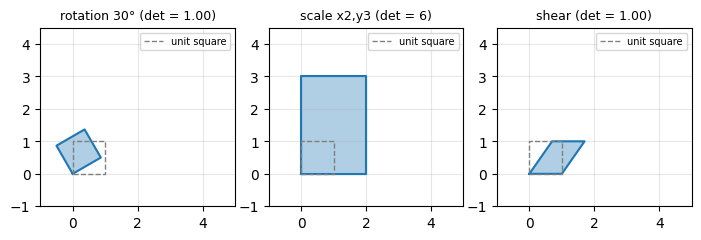

area scaling |det|: rotation 1.00 (preserves area), scale 6, shear 1.00


In [45]:
# unit square through each transform: determinant = area factor
square = np.array([[0.0, 0], [1, 0], [1, 1], [0, 1]])      # 4 corners
fig, axes = plt.subplots(1, 3, figsize=(7, 2.8))
for ax, (M, name) in zip(axes, [(R, "rotation 30° (det = %.2f)" % np.linalg.det(R)),
                                (S, "scale x2,y3 (det = %.0f)" % np.linalg.det(S)),
                                (Sh, "shear (det = %.2f)" % np.linalg.det(Sh))]):
    img = square @ M.T                                     # transform each corner
    ax.fill(img[:, 0], img[:, 1], alpha=0.35, color="tab:blue")
    ax.plot(*np.append(img, img[:1], axis=0).T, color="tab:blue", lw=1.5)
    ax.plot(*np.append(square, square[:1], axis=0).T, color="gray",
            ls="--", lw=1, label="unit square")
    ax.set_title(name, fontsize=9)
    ax.set_aspect("equal")
    ax.grid(True, alpha=0.3)
    ax.set_xlim(-1, 5)
    ax.set_ylim(-1, 4.5)
    ax.legend(fontsize=7, loc="upper right")
plt.tight_layout()
plt.show()
print("area scaling |det|: rotation %.2f (preserves area), scale %.0f, shear %.2f"
      % (abs(np.linalg.det(R)), abs(np.linalg.det(S)), abs(np.linalg.det(Sh))))


In [46]:
# eigenvectors = the directions that do NOT rotate (only get stretched)
A = np.array([[3.0, 1],
              [0, 2]])
w, V = np.linalg.eig(A)

def angle_between(a, b):
    c = np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))
    return np.degrees(np.arccos(np.clip(c, -1, 1)))

eig_v = V[:, 0]
other = np.array([1.0, 0.4])
print("eigen-direction  v =", np.round(eig_v, 4),
      " -> angle(v, A v) = %.6f°" % angle_between(eig_v, A @ eig_v))
print("arbitrary vector u =", other,
      " -> angle(u, A u) = %.3f°  (rotated!)" % angle_between(other, A @ other))


eigen-direction  v = [1. 0.]  -> angle(v, A v) = 0.000000°
arbitrary vector u = [1.  0.4]  -> angle(u, A u) = 8.561°  (rotated!)


### SVD = rotate → scale → rotate (the picture to remember)

```text
       V^T (transpose/rotate)      Σ (scale the axes)        U (rotate)
  x  ----------------------->  x'  ----------------->  x''  ------------>  A x
       right singular basis          by sigma_1, sigma_2      left singular basis
```

Every matrix, no matter how messy, **is just a rotation, an axis-aligned
stretch, and another rotation** — that's why SVD exists for non-square matrices
where eigen-decomposition does not.

### Why ML engineers live in this notebook

| ML thing | Linear algebra underneath |
|---|---|
| dataset `X (n × p)` | a matrix of row-vectors (samples) |
| linear regression / perceptron | `X @ w + b`, least squares projection |
| PCA / eigendecomposition | `eigh(cov(X))` (§11) |
| word/image embeddings | cosine similarity of vectors (§2) |
| covariance & Mahalanobis distance | symmetric PSD matrix, $d=\sqrt{(x-\mu)^\top\Sigma^{-1}(x-\mu)}$ |
| gradients & Jacobians / Hessians | matrix of partial derivatives |
| batch forward pass | `X @ W + b` (§6 `@`!) |
| attention (transformers) | $\text{softmax}(QK^\top/\sqrt d)\,V$ — three matmuls |
| recommender (matrix factorisation) | truncated SVD (§12) |
| normalisation layers | mean/var of rows, then scale (§3 norms) |
| optimisation stability | condition number, positive definiteness (§8, §11) |

In [47]:
# **Section notes — geometry:**
#
# | Transform | Matrix | Signature |
# |---|---|---|
# | rotation | $\begin{pmatrix}\cos\theta & -\sin\theta\\ \sin\theta & \cos\theta\end{pmatrix}$ | $\det = 1$, orthogonal |
# | scale | $\text{diag}(s_1, s_2)$ | $\det = s_1 s_2$ |
# | shear | $\begin{pmatrix}1&k\\0&1\end{pmatrix}$ | $\det = 1$ (area preserved!) |
# | eigenvector | $A\mathbf v = \lambda \mathbf v$ | direction unchanged |
# | SVD | $A = U\Sigma V^\top$ | rotate → scale → rotate |


---
## 15. NumPy/sympy cheatsheet + interview Q&A

### Function cheatsheet — function → purpose → gotcha

| Function | Purpose | Gotcha |
|---|---|---|
| `u @ v` / `np.dot(u, v)` | dot product | for 2-D it's matrix mult, not element-wise |
| `A * B` | Hadamard (element-wise) | **never** matrix multiplication |
| `np.linalg.norm(v, ord=)` | L1/L2/L∞ norms | matrix default = Frobenius |
| `np.linalg.matrix_rank(A)` | rank via SVD | float tolerance, not exact |
| `scipy.linalg.null_space(A)` | null-space basis | columns are the basis vectors |
| `np.linalg.det(A)` | determinant | float: use `abs < tol`, never `== 0` |
| `np.linalg.inv(A)` | inverse | square + non-singular only; prefer `solve` |
| `np.linalg.solve(A, b)` | solve `Ax = b` | raises `LinAlgError` if singular |
| `np.linalg.pinv(A)` | Moore-Penrose inverse | works for rectangular/singular |
| `np.linalg.lstsq(X, y, rcond=None)` | least squares | `rcond=None` = modern default |
| `np.linalg.eig(A)` | eigenvalues/vectors | square only; may be **complex** |
| `np.linalg.eigh(A)` | symmetric eigen | real, ascending, orthonormal → **use for covariance** |
| `np.linalg.svd(A, full_matrices=False)` | SVD | returns $V^\top$, $\sigma \ge 0$ descending |
| `np.linalg.qr(A)` | QR factorisation | `Q` columns orthonormal |
| `np.linalg.cholesky(A)` | Cholesky $LL^\top$ | **positive definite** only |
| `np.linalg.cond(A)` | condition number | ≫ 1 → numerically dangerous |
| `np.trace(A)` | sum of diagonal | `sum(eigenvalues)` too |
| `sp.Matrix(A).eigenvects()` | exact eigen | rational arithmetic, slower |
| `sp.Matrix(A).rref()` | row echelon | returns `(matrix, pivot cols)` |

### 10 rapid-fire interview questions

1. **What does `det = 0` mean?** — the transform squashes volume: columns are
   linearly dependent (rank-deficient), no inverse exists, `Ax = 0` has
   non-trivial solutions, and `solve` raises `LinAlgError`.
2. **Why is $(AB)^{-1} = B^{-1}A^{-1}$?** — apply in order: $A(BB^{-1})A^{-1} = I$.
   The order flips, exactly like $(AB)^\top = B^\top A^\top$ (undo in reverse).
3. **eig vs SVD?** — eig needs a **square** matrix and can produce complex
   values for non-symmetric input; SVD works for **any** $m\times n$, always
   gives real non-negative singular values with $U, V$ orthonormal. For
   symmetric $A$: $A = Q\Lambda Q^\top$ is an SVD with $|\lambda| = \sigma$.
4. **Rank vs dimension?** — dimension is the space you live in (columns $n$);
   rank is how many *independent* directions the data actually uses
   ($\le \min(m,n)$). rank = number of non-zero singular values.
5. **What does positive definite mean?** — symmetric with all eigenvalues $> 0$
   (⟺ $\mathbf x^\top A \mathbf x > 0 \ \forall \mathbf x\ne0$ ⟺ Cholesky exists).
   Covariance matrices are PSD; adding $\epsilon I$ makes them PD (ridge trick).
6. **Why `solve` instead of `inv`?** — one LU factorisation, fewer flops, and
   no extra squaring of the condition number; explicit inverses are also
   ill-advised numerically (§8 demo).
7. **Relation between singular values and eigenvalues?** — $\sigma_i^2$ =
   eigenvalues of $A^\top A$ (non-negative), while eigenvalues of $A$ itself can
   be negative or complex; $AA^\top$ and $A^\top A$ share the same $\sigma^2$.
8. **Orthogonal vs orthonormal?** — orthogonal = vectors pairwise perpendicular
   (dot = 0); **ortho**normal = orthogonal **and each of unit length**
   ($Q^\top Q = I$). An orthogonal *matrix* has orthonormal rows and columns.
9. **Give a case where matrix multiplication isn't commutative.** — rotations:
   rotate 30° then scale ≠ scale then rotate (we computed both above); in ML the
   order $W_2(W_1x)$ vs $W_1(W_2x)$ changes the function, which is why layer
   order in networks matters.
10. **How does PCA use eigendecomposition?** — standardise $X$, take
    $\text{cov}(X)$ (symmetric PSD), `eigh` → eigenvalues = variance along each
    principal axis, eigenvectors = the axes; keep the top-k and project
    `Xs @ evecs`. Equivalently, SVD of $X$ directly.

---
## Quick revision sheet

| Task | Code |
|---|---|
| dot product / angle | `u @ v` · `arccos(u@v/(norm u · norm v))` |
| cosine similarity | `u @ v / (norm(u) * norm(v))` |
| L1 / L2 / L∞ norm | `np.linalg.norm(v, ord=1 / 2 / np.inf)` |
| unit vector | `v / np.linalg.norm(v)` |
| pairwise distances | `np.linalg.norm(pts[:, None] - pts[None, :], axis=-1)` |
| rank / null space | `np.linalg.matrix_rank(A)` · `sla.null_space(A)` |
| symmetric / orthogonal check | `np.allclose(A, A.T)` · `np.allclose(A.T @ A, I)` |
| matrix product | `A @ B` (inner dims must match: m,k @ k,n) |
| element-wise product | `A * B` (Hadamard) |
| transpose rule | `(A @ B).T == B.T @ A.T` |
| determinant | `np.linalg.det` · `sp.Matrix(...).det()` |
| solve `Ax=b` | `np.linalg.solve(A, b)` (never `inv(A) @ b`) |
| eigen | `w, V = np.linalg.eig(A)` · symmetric → `eigh` |
| diagonalise | `P @ diag(w) @ inv(P)` |
| SVD | `U, s, Vt = svd(A, full_matrices=False)` · rank = `#(s > tol)` |
| best rank-k | `(U[:, :k] * s[:k]) @ Vt[:k]` |
| pseudoinverse | `np.linalg.pinv(A)` = `V diag(1/σ) U^T` |
| projection | `(u @ v) / (v @ v) * v` |
| least squares / QR | `lstsq(X, y)` · `Q, R = qr(X); solve(R, Q.T @ y)` |
| PCA in 5 lines | standardise → `np.cov` → `eigh` → sort → `Xs @ evecs` |

> **Interview short-list:** `@` vs `*` · det = 0 meaning · $(AB)^{-1}$ order flip ·
> eig vs svd · rank vs dimension · positive definite · why `solve` over `inv` ·
> orthonormal vs orthogonal · $A = U\Sigma V^\top$ picture ·
> eigenvectors don't rotate · PCA = eigendecomposition of covariance.

---
**Next notebook:** `10_ml_fundamentals_regression.ipynb` — where these matrices
become models: linear regression via the normal equations.

**Playlist:** https://www.youtube.com/playlist?list=PLKnIA16_RmvbAlyx4_rdtR66B7EHX5k3z